# Fase 2 · Entrenamiento en GCP del modelo de riesgo crediticio

**Entregable final — Ciencia de Datos en Producción.** Este notebook compara tres
formas de entrenar el modelo de clasificación de créditos del repositorio CDProd:

| Enfoque | Dónde corre | Qué entrena |
|---|---|---|
| **Python local** | PC del estudiante | Flujo del repo: `cargar_datos → preparar_datos → entrenar → evaluar` |
| **Vertex Pipelines (custom)** | GCP, pipeline KFP v2 | El **mismo código del repo** (commit fijo), con 5 semillas de partición en paralelo |
| **AutoML Tabular** | GCP, Vertex AI | Búsqueda automática de modelo, 1 nodo-hora, objetivo ROC-AUC |

**Diseño para una comparación justa**

- Misma tabla de origen (`cdprod-upb-mg.novabank_dev.Creditos`, 10.763 registros) y las
  mismas **15 variables RAW** del modelo del repo (se excluyen saldos, puntaje y huella por leakage).
- Mismo **holdout**: el 20 % estratificado de `preparar_datos(random_state=42)`
  (2.153 filas, 102 de riesgo). En AutoML ese holdout es el split `TEST`; del train se aparta
  un 10 % como `VALIDATE`.
- Mismas métricas para todos (`vertex/metricas.py`), con la **clase de riesgo = 0** como positiva.

Scripts: `vertex/preparar_tabla_vertex.py`, `vertex/automl_entrenar.py`,
`vertex/automl_evaluar.py`, `vertex/pipeline_custom.py`, `vertex/python_local.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

RES = Path("resultados") if Path("resultados").exists() else Path("vertex/resultados")
FIG = RES.resolve().parent.parent / "entregable" / "capturas" / "fase2"
FIG.mkdir(parents=True, exist_ok=True)

def leer(nombre):
    return json.loads((RES / f"{nombre}.json").read_text(encoding="utf-8"))

local = leer("python_local_metricas")
pipe = leer("pipeline_metricas")
automl = leer("automl_metricas")
automl_job = leer("automl_job")
tabla_vertex = leer("tabla_vertex")
pipe_42 = next(f for f in pipe["consolidado"]["por_semilla"] if f["semilla_split"] == 42)

# Paleta categórica validada (orden fijo: el color sigue al enfoque).
COLORES = {
    "Python local": "#2a78d6",
    "Vertex Pipelines": "#eb6834",
    "AutoML (umbral 0.5)": "#1baf7a",
    "AutoML (umbral validación)": "#eda100",
}
TEXTO, TEXTO_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "font.size": 10,
})
print("Tabla Vertex:", tabla_vertex["tabla"], "| filas:", tabla_vertex["filas"])
print("Conteos por split y clase:", tabla_vertex["conteos_split_por_clase"])

Tabla Vertex: cdprod-upb-mg.novabank_dev.creditos_vertex | filas: 10763
Conteos por split y clase: {'0': {'TEST': 102, 'TRAIN': 368, 'VALIDATE': 41}, '1': {'TEST': 2051, 'TRAIN': 7381, 'VALIDATE': 820}}


## 1. Métricas de desempeño sobre el mismo holdout

AutoML predice la clase con umbral 0.5. Como la clase de riesgo es solo el 4,7 %,
ese umbral casi nunca marca riesgo. Por eso AutoML se reporta dos veces:

- **umbral 0.5**: salida por defecto de AutoML;
- **umbral validación**: el que maximiza F1 de riesgo en `VALIDATE`, aplicado sin cambios a `TEST`
  (el holdout nunca se usa para elegirlo).

El modelo del repo (LogisticRegression con `class_weight="balanced"`) ya compensa el
desbalance, así que su `predict()` equivale a umbral 0.5 sobre la probabilidad de riesgo.
ROC-AUC y Average Precision no dependen del umbral y son la comparación más limpia.

In [2]:
METRICAS = ["accuracy", "balanced_accuracy", "f1_0", "recall_0", "precision_0",
            "roc_auc_risk", "average_precision_risk", "rmse_prob_riesgo"]
NOMBRES = {
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy", "f1_0": "F1 (riesgo)",
    "recall_0": "Recall (riesgo)", "precision_0": "Precision (riesgo)", "roc_auc_risk": "ROC-AUC",
    "average_precision_risk": "Average precision", "rmse_prob_riesgo": "RMSE probabilidad",
}
filas = {
    "Python local": local["test_umbral_0_5"],
    "Vertex Pipelines": {**pipe_42, "rmse_prob_riesgo": np.nan},
    "AutoML (umbral 0.5)": automl["test_umbral_0_5"],
    "AutoML (umbral validación)": automl["test_umbral_validacion"],
}
comparativa = pd.DataFrame({k: {m: v.get(m, np.nan) for m in METRICAS} for k, v in filas.items()}).T
comparativa = comparativa.rename(columns=NOMBRES)
comparativa["Umbral"] = [0.5, 0.5, 0.5, automl["test_umbral_validacion"]["umbral"]]
comparativa.round(4)

,Accuracy,Balanced accuracy,F1 (riesgo),Recall (riesgo),Precision (riesgo),ROC-AUC,Average precision,RMSE probabilidad,Umbral
Python local,0.6307,0.5826,0.1196,0.5294,0.0674,0.5995,0.0968,0.4787,0.5000
Vertex Pipelines,0.6307,0.5826,0.1196,0.5294,0.0674,0.5995,0.0968,NaN,0.5000
AutoML (umbral 0.5),0.9489,0.5167,0.0678,0.0392,0.2500,0.6882,0.1490,0.2109,0.5000
AutoML (umbral validación),0.9271,0.5844,0.2111,0.2059,0.2165,0.6882,0.1490,0.2109,0.1196


**Dos detalles de AutoML que cambian la lectura**

1. **Nulos.** `promedio_ingresos_datacredito` está vacío en ~28 % de los créditos (33 de los
   102 casos de riesgo del holdout). Con la transformación numérica por defecto
   (`invalid_values_allowed = false`), AutoML **descarta esas filas al entrenar** y las
   **rechaza al predecir** (*"Null values are not allowed in transformations"*). Para evaluarlo
   sobre el holdout completo, `automl_evaluar.py` imputa esos nulos con la mediana de `TRAIN`,
   lo mismo que hace el `SimpleImputer(median)` del pipeline local. El modelo local, en cambio,
   sí aprende de esas filas.
2. **Evaluación nativa de la consola.** Vertex reporta un `auRoc` muy alto en la pestaña
   *Evaluate*. Ese valor es **micro-promediado sobre las dos clases** y está dominado por la clase
   mayoritaria (pago a tiempo, 95 %), además de calcularse solo sobre filas sin nulos. No es
   comparable con el ROC-AUC de la clase de riesgo de la tabla anterior.

In [3]:
nativa = automl["evaluacion_nativa_vertex_test"]
pd.DataFrame({
    "Vertex (consola, micro-promedio)": [nativa.get("auRoc"), nativa.get("auPrc")],
    "Calculado aquí (clase de riesgo, holdout completo)": [
        automl["test_umbral_0_5"]["roc_auc_risk"], automl["test_umbral_0_5"]["average_precision_risk"]],
}, index=["ROC-AUC", "PR-AUC / Average precision"]).round(4)

,"Vertex (consola, micro-promedio)","Calculado aquí (clase de riesgo, holdout completo)"
ROC-AUC,0.9667,0.6882
PR-AUC / Average precision,0.9594,0.1490


**¿Dónde gana AutoML?** Se separa el holdout según si el crédito traía
`promedio_ingresos_datacredito` o si hubo que imputarlo.

In [4]:
from sklearn.metrics import average_precision_score, roc_auc_score

_a = pd.read_csv(RES / "automl_scores_test.csv")
_l = pd.read_csv(RES / "python_local_scores_test.csv")
_d = _l.merge(_a[["fila_id", "score_riesgo", "imputado"]], on="fila_id", suffixes=("_local", "_automl"))
filas_nulos = []
for nombre, g in (("Holdout completo", _d), ("Con dato de ingresos", _d[~_d.imputado]),
                  ("Sin dato (imputado)", _d[_d.imputado])):
    y = (g.y == 0).astype(int)
    filas_nulos.append({
        "Subconjunto": nombre, "Créditos": len(g), "Casos de riesgo": int(y.sum()),
        "ROC-AUC local": roc_auc_score(y, g.score_riesgo_local),
        "ROC-AUC AutoML": roc_auc_score(y, g.score_riesgo_automl),
        "AP local": average_precision_score(y, g.score_riesgo_local),
        "AP AutoML": average_precision_score(y, g.score_riesgo_automl),
    })
pd.DataFrame(filas_nulos).set_index("Subconjunto").round(4)

,Créditos,Casos de riesgo,ROC-AUC local,ROC-AUC AutoML,AP local,AP AutoML
Subconjunto,,,,,,
Holdout completo,2153,102,0.5995,0.6882,0.0968,0.1490
Con dato de ingresos,1548,69,0.6107,0.7535,0.1311,0.2594
Sin dato (imputado),605,33,0.5433,0.5456,0.0602,0.0650


Con el dato de ingresos de Datacrédito, AutoML separa bastante mejor el riesgo que el modelo
local. Sin ese dato (28 % de los créditos), **ambos modelos quedan cerca del azar**: la
diferencia entre ellos viene de cómo explotan la información disponible, no de un mejor manejo
de los faltantes.

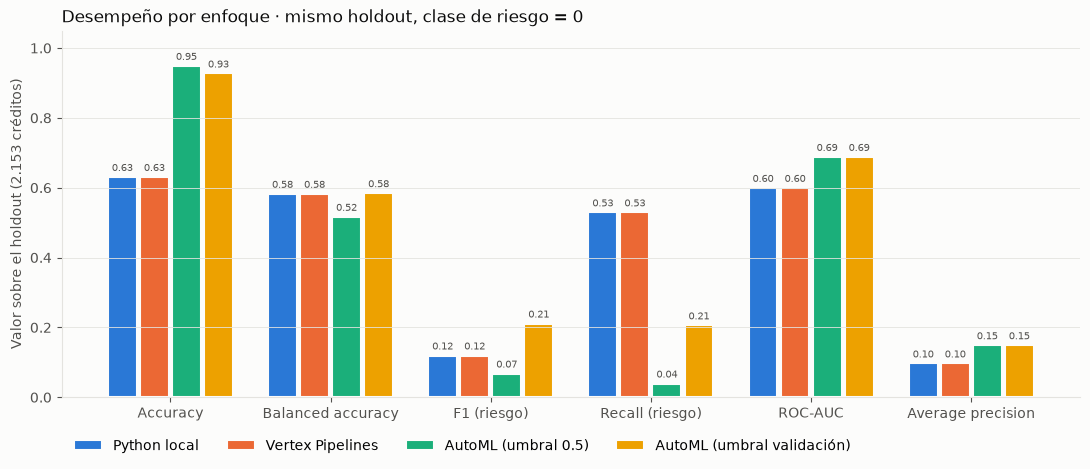

In [5]:
mostrar = ["Accuracy", "Balanced accuracy", "F1 (riesgo)", "Recall (riesgo)", "ROC-AUC", "Average precision"]
fig, ax = plt.subplots(figsize=(11, 4.8))
n = len(comparativa)
ancho = 0.8 / n
x = np.arange(len(mostrar))
for i, (enfoque, fila) in enumerate(comparativa[mostrar].iterrows()):
    pos = x - 0.4 + ancho * (i + 0.5)
    barras = ax.bar(pos, fila.values, width=ancho * 0.9, color=COLORES[enfoque], label=enfoque,
                    edgecolor="#fcfcfb", linewidth=1.5)
    for b, v in zip(barras, fila.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center",
                va="bottom", fontsize=7.5, color=TEXTO_2)
ax.set_xticks(x, mostrar)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor sobre el holdout (2.153 créditos)")
ax.set_title("Desempeño por enfoque · mismo holdout, clase de riesgo = 0", color=TEXTO, loc="left")
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.08))
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "01_metricas_por_enfoque.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Curvas ROC y Precision-Recall (Python local vs AutoML)

Ambos modelos se evalúan sobre las mismas 2.153 filas (`fila_id`). La línea gris
punteada es el azar: diagonal en ROC y la tasa de riesgo (4,7 %) en Precision-Recall.

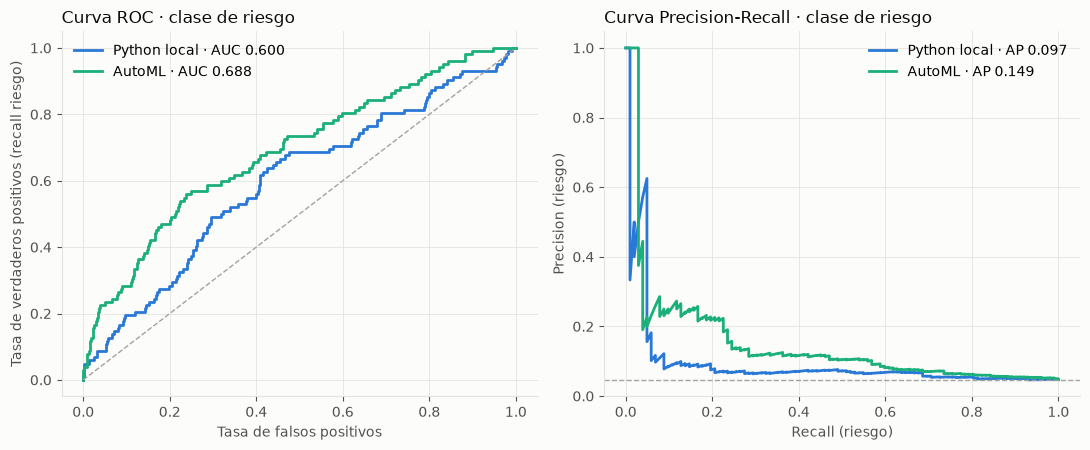

In [6]:
s_local = pd.read_csv(RES / "python_local_scores_test.csv")
s_automl = pd.read_csv(RES / "automl_scores_test.csv")
assert set(s_local.fila_id) == set(s_automl.fila_id), "Los holdouts no coinciden"

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
for nombre, s, auc_k, ap_k in (
    ("Python local", s_local, local["test_umbral_0_5"]["roc_auc_risk"], local["test_umbral_0_5"]["average_precision_risk"]),
    ("AutoML (umbral 0.5)", s_automl, automl["test_umbral_0_5"]["roc_auc_risk"], automl["test_umbral_0_5"]["average_precision_risk"]),
):
    y = (s.y == 0).astype(int)
    fpr, tpr, _ = roc_curve(y, s.score_riesgo)
    pr, rc, _ = precision_recall_curve(y, s.score_riesgo)
    etiqueta = nombre.replace(" (umbral 0.5)", "")
    a1.plot(fpr, tpr, color=COLORES[nombre], lw=2, label=f"{etiqueta} · AUC {auc_k:.3f}")
    a2.plot(rc, pr, color=COLORES[nombre], lw=2, label=f"{etiqueta} · AP {ap_k:.3f}")
a1.plot([0, 1], [0, 1], ls="--", color="#a3a29d", lw=1)
tasa = (s_local.y == 0).mean()
a2.axhline(tasa, ls="--", color="#a3a29d", lw=1)
a1.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall riesgo)")
a2.set(xlabel="Recall (riesgo)", ylabel="Precision (riesgo)")
a1.set_title("Curva ROC · clase de riesgo", color=TEXTO, loc="left")
a2.set_title("Curva Precision-Recall · clase de riesgo", color=TEXTO, loc="left")
for a in (a1, a2):
    a.legend(frameon=False, loc="best")
fig.tight_layout()
fig.savefig(FIG / "02_curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Consistencia: el mismo código en la PC y en Vertex Pipelines

El componente `entrenar-evaluar` descarga el repositorio en el commit `4a2fc81` y ejecuta
exactamente el flujo local. Con la semilla 42, el resultado en la nube debe coincidir
con el local, aunque cambie la máquina (12 hilos locales frente a un contenedor de 4 vCPU en GCP).

In [7]:
consistencia = pd.DataFrame({
    "Python local": {m: local["test_umbral_0_5"][m] for m in ["f1_0", "recall_0", "precision_0", "balanced_accuracy", "roc_auc_risk"]},
    "Vertex Pipelines (semilla 42)": {m: pipe_42[m] for m in ["f1_0", "recall_0", "precision_0", "balanced_accuracy", "roc_auc_risk"]},
}).rename(index=NOMBRES)
consistencia["Diferencia absoluta"] = (consistencia.iloc[:, 0] - consistencia.iloc[:, 1]).abs()
print("Modelo local:", local["modelo"], local["hiperparametros"], "| Vertex:", pipe_42["modelo_final"], pipe_42["hiperparametros"])
consistencia.round(6)

Modelo local: logistic_regression {'model__C': '10.0'} | Vertex: logistic_regression {'model__C': '10.0'}


,Python local,Vertex Pipelines (semilla 42),Diferencia absoluta
F1 (riesgo),0.119601,0.119601,0.0
Recall (riesgo),0.529412,0.529412,0.0
Precision (riesgo),0.067416,0.067416,0.0
Balanced accuracy,0.582600,0.582600,0.0
ROC-AUC,0.599511,0.599511,0.0


## 4. Estabilidad: cinco particiones train/holdout en Vertex Pipelines

El `ParallelFor` del pipeline repite selección de modelo, tuning y evaluación con
5 semillas de partición (42, 7, 13, 21, 99). Si el modelo fuera estable, las métricas
variarían poco y siempre ganaría la misma familia.

In [8]:
semillas = pd.DataFrame(pipe["consolidado"]["por_semilla"]).set_index("semilla_split")
tabla_sem = semillas[["modelo_final", "f1_0", "recall_0", "precision_0", "balanced_accuracy", "roc_auc_risk", "tiempo_entrenamiento_s"]]
resumen = pd.DataFrame({
    "media": tabla_sem.drop(columns="modelo_final").mean(),
    "desv. estándar": tabla_sem.drop(columns="modelo_final").std(ddof=1),
})
resumen["coef. variación"] = resumen["desv. estándar"] / resumen["media"]
display(tabla_sem.round(4))
resumen.round(4)

,modelo_final,f1_0,recall_0,precision_0,balanced_accuracy,roc_auc_risk,tiempo_entrenamiento_s
semilla_split,,,,,,,
42,logistic_regression,0.1196,0.5294,0.0674,0.5826,0.5995,17.04
7,hist_gradient_boosting,0.1792,0.1863,0.1727,0.5710,0.6231,203.70
13,hist_gradient_boosting,0.1069,0.1373,0.0875,0.5330,0.5591,205.62
21,logistic_regression,0.1346,0.5686,0.0763,0.6132,0.6631,21.92
99,hist_gradient_boosting,0.1561,0.1569,0.1553,0.5572,0.6293,180.20


,media,desv. estándar,coef. variación
f1_0,0.1393,0.0289,0.2075
recall_0,0.3157,0.2142,0.6784
precision_0,0.1119,0.0485,0.4340
balanced_accuracy,0.5714,0.0298,0.0521
roc_auc_risk,0.6148,0.0385,0.0627
tiempo_entrenamiento_s,125.6960,97.4920,0.7756


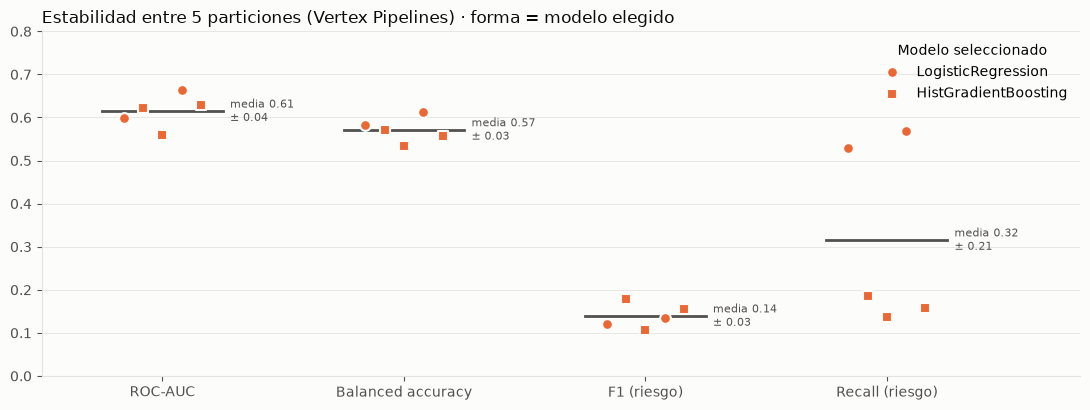

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.2))
metricas_est = ["roc_auc_risk", "balanced_accuracy", "f1_0", "recall_0"]
FAMILIA = {"logistic_regression": ("o", "LogisticRegression"), "hist_gradient_boosting": ("s", "HistGradientBoosting"), "random_forest": ("^", "RandomForest")}
vistos = set()
for j, m in enumerate(metricas_est):
    vals = tabla_sem[m]
    ax.plot([j - 0.25, j + 0.25], [vals.mean()] * 2, color=TEXTO_2, lw=2)
    for k, (sem, fila) in enumerate(tabla_sem.iterrows()):
        marca, nombre = FAMILIA.get(fila.modelo_final, ("D", fila.modelo_final))
        ax.scatter(j - 0.16 + 0.08 * k, fila[m], s=60, marker=marca, color=COLORES["Vertex Pipelines"],
                   edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label=None if nombre in vistos else nombre)
        vistos.add(nombre)
    ax.text(j + 0.28, vals.mean(), f"media {vals.mean():.2f}\n± {vals.std(ddof=1):.2f}", va="center", fontsize=8, color=TEXTO_2)
ax.set_xticks(range(len(metricas_est)), [NOMBRES[m] for m in metricas_est])
ax.set_xlim(-0.5, len(metricas_est) - 0.2)
ax.set_ylim(0, 0.8)
ax.set_title("Estabilidad entre 5 particiones (Vertex Pipelines) · forma = modelo elegido", color=TEXTO, loc="left")
ax.legend(frameon=False, loc="upper right", title="Modelo seleccionado")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "03_estabilidad_semillas.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Tiempos de ejecución y costos

In [10]:
dur = {t["tarea"]: t["duracion_s"] for t in pipe["tareas"]}
entrenar_tareas = [t["duracion_s"] for t in pipe["tareas"] if t["tarea"] == "entrenar-evaluar"]
tiempos = pd.DataFrame([
    {"Enfoque": "Python local", "Entrenamiento (cómputo)": f"{local['tiempo_entrenamiento_s']:.0f} s",
     "Duración total de punta a punta": f"{local['tiempo_carga_s'] + local['tiempo_entrenamiento_s']:.0f} s",
     "Recursos": f"PC local, {local['cpu_count']} hilos (CPU)", "Costo GCP aprox.": "USD 0"},
    {"Enfoque": "Vertex Pipelines (5 semillas)", "Entrenamiento (cómputo)": f"{semillas.tiempo_entrenamiento_s.min():.0f}–{semillas.tiempo_entrenamiento_s.max():.0f} s por semilla",
     "Duración total de punta a punta": f"{pipe['duracion_total_s'] / 60:.1f} min (incluye aprovisionar contenedores e instalar dependencias)",
     "Recursos": "5 contenedores e2-standard-4 en paralelo (4 vCPU, CPU)", "Costo GCP aprox.": "≈ USD 0.17 (5 × e2-standard-4 + USD 0.03 por corrida)"},
    {"Enfoque": "AutoML Tabular", "Entrenamiento (cómputo)": "1 nodo-hora de presupuesto",
     "Duración total de punta a punta": f"{automl['tiempo_entrenamiento_min']:.0f} min",
     "Recursos": "Gestionado por Google (CPU, búsqueda de arquitecturas y ensamble)", "Costo GCP aprox.": "≈ USD 21.25 (1 nodo-hora × USD 21.252)"},
    {"Enfoque": "AutoML · batch prediction", "Entrenamiento (cómputo)": "—",
     "Duración total de punta a punta": f"{automl['tiempo_batch_prediction_s'] / 60:.1f} min para {automl['n_validate'] + automl['n_test']:,} filas (la mayor parte es encender la máquina)",
     "Recursos": "1 nodo n1-standard-4", "Costo GCP aprox.": "centavos (confirmar en Facturación)"},
])
tiempos.set_index("Enfoque")

,Entrenamiento (cómputo),Duración total de punta a punta,Recursos,Costo GCP aprox.
Enfoque,,,,
Python local,26 s,36 s,"PC local, 12 hilos (CPU)",USD 0
Vertex Pipelines (5 semillas),17–206 s por semilla,11.2 min (incluye aprovisionar contenedores e ...,5 contenedores e2-standard-4 en paralelo (4 vC...,≈ USD 0.17 (5 × e2-standard-4 + USD 0.03 por c...
AutoML Tabular,1 nodo-hora de presupuesto,162 min,"Gestionado por Google (CPU, búsqueda de arquit...",≈ USD 21.25 (1 nodo-hora × USD 21.252)
AutoML · batch prediction,—,"10.3 min para 3,014 filas (la mayor parte es e...",1 nodo n1-standard-4,centavos (confirmar en Facturación)


Precios de lista en `us-central1` (noviembre de 2026): AutoML Tabular USD 21,252 por nodo-hora
de entrenamiento; Vertex Pipelines USD 0,03 por corrida más el cómputo (e2-standard-4 ≈ USD 0,154/h).
Las 2 h 41 min de AutoML son tiempo de reloj; lo que se factura es el presupuesto de 1 nodo-hora.
Detalle y fuentes en `entregable/fase3_investigacion.md`.

## 6. Python manual vs AutoML: beneficios y límites

| | Entrenamiento manual (Python local / Vertex Pipelines) | AutoML Tabular |
|---|---|---|
| **Capacidad de ranking** | ROC-AUC 0,600 · AP 0,097 | **ROC-AUC 0,688 · AP 0,149** (+15 % y +54 %) |
| **Métrica de negocio (F1 riesgo)** | 0,120 con umbral 0,5 (recall 0,53, precision 0,07) | 0,068 con umbral 0,5; **0,211** con umbral elegido en VALIDATE (recall 0,21, precision 0,22) |
| **Control del modelado** | Total: variables, imputación, `class_weight`, selección por F1 de riesgo | Optimiza ROC-AUC; el umbral 0,5 por defecto casi no marca riesgo (16 de 2.153) y hay que calibrarlo aparte |
| **Datos faltantes** | Imputación explícita, aprende de todas las filas | Por defecto descarta en entrenamiento y rechaza en predicción las filas con nulos numéricos |
| **Reproducibilidad** | Exacta: mismo commit ⇒ mismas métricas en la PC y en la nube | Caja negra; repetir la búsqueda cuesta otra vez el presupuesto completo |
| **Tiempo** | 26 s local; 11 min en Vertex con 5 semillas | 2 h 41 min de entrenamiento + 10 min de batch prediction |
| **Costo** | ≈ USD 0 local; ≈ USD 0,17 en Vertex | ≈ USD 21 por entrenamiento |
| **Esfuerzo de código** | Todo el pipeline del repo (EDA, features, CV, tuning, evaluación) | Ninguno de modelado: tabla en BigQuery + tipos de columna |
| **Integración CI/CD** | Directa: el quality gate de Jenkins ejecuta el mismo código | Requiere orquestar la API de Vertex y esperar horas por corrida |

**Lectura.** AutoML encontró una señal que el modelo manual no explota (sobre todo en los créditos con dato
de ingresos), con cero código de modelado. El precio es menos control: hubo que detectar a mano el problema de
nulos, ignorar la métrica nativa de la consola y calibrar el umbral, y cada intento cuesta ~USD 21 y casi
3 horas. El entrenamiento manual es barato, rápido, reproducible y ya está gobernado por el quality gate de
Jenkins, pero se queda corto en capacidad predictiva.

## 7. Conclusiones: estabilidad y consistencia

1. **Consistencia (infraestructura).** El mismo commit produce exactamente las mismas métricas en la PC
   (12 hilos) y en un contenedor de Vertex Pipelines (4 vCPU): diferencia 0 en todas las métricas. El resultado
   depende del código y de los datos, no de dónde corre.
2. **Estabilidad (datos).** Entre 5 particiones, el ROC-AUC del modelo manual varía 0,615 ± 0,039 y el recall
   de riesgo 0,32 ± 0,21; incluso cambia la familia ganadora (LogisticRegression en 2 semillas,
   HistGradientBoosting en 3). Con solo ~500 casos de riesgo, qué créditos caen en el holdout pesa tanto
   como el algoritmo.
3. **AutoML frente a esa variabilidad.** Su ROC-AUC (0,688) queda unas 1,9 desviaciones estándar por encima
   de la media del modelo manual entre semillas, así que la mejora probablemente no es solo ruido de la
   partición. Pero AutoML se evaluó en una sola partición: medir su propia estabilidad costaría ~USD 21 por
   semilla.
4. **Umbral y desbalance.** Ninguno de los dos enfoques sirve con el umbral 0,5 sin pensarlo: el modelo manual
   marca 801 créditos como riesgo (muchos falsos positivos) y AutoML solo 16. El umbral es una decisión de
   negocio que debe fijarse con un conjunto de validación, nunca con el holdout.
5. **Siguiente paso.** Reentrenar AutoML con `invalid_values_allowed=True` para que aprenda de las filas sin
   dato de ingresos, y llevar al pipeline manual lo que AutoML sugiere (modelos de boosting con más
   regularización y un indicador de dato faltante), manteniendo el quality gate de Jenkins como control.